# 11climatology: is 2026 unusual, and what do typhoons do to the haze? (2003 to 2026)

Part C of PF5, the seed for the paper. Uses the MERRA-2 daily files from `10merra2` and the typhoon days and climate indices from `09tracks`; no downloads.

| Section | Question |
|---|---|
| 2 | Combine the 2,178 daily files into one dataset (smoke, PM2.5, smoke column, smoke flux) |
| 3 | Does MERRA-2 agree with GEOS-FP for August and September 2026? |
| 4 | How does 2026 compare with 23 seasons, and how much do El Nino and the Indian Ocean Dipole explain? |
| 5 | **Direct export**: on typhoon days, does more smoke flow from eastern Indonesia into the Pacific corridor? |
| 6 | **Indirect effect**: on typhoon days, is the smoke over Sumatra, Kalimantan, Kuala Lumpur and Singapore higher or lower than usual? Split by El Nino years |
| 7 | What happens day by day before and after a typhoon enters the Philippine Sea |
| 8 | Map of the typhoon-day difference with a significance test |

**Definitions (the same as Part B).** Typhoon day: a system of at least 64 knots in the Philippine Sea box (120E to 150E, 5N to 25N). Anomaly: a day's value minus its own 15-day running mean within the season, so that the season's build-up and year-to-year differences drop out. Uncertainty: **whole seasons are resampled** (a "cluster bootstrap" over years), because days within one season are not independent.

**Smoke in MERRA-2** = organic + black carbon. MERRA-2 has no separate brown carbon; its organic carbon includes fire smoke but also urban and plant sources, so the analysis uses regions where fire smoke dominates in this season. **PM2.5** follows the formula commonly used for MERRA-2 (Buchard et al. 2016): dust 2.5 + sea salt 2.5 + black carbon + 1.4 x organic carbon + 1.375 x sulfate.

## Section 0: settings

In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
M2_DIR = PROJECT_DIR / "data" / "raw" / "merra2"
CLIM_DIR = PROJECT_DIR / "data" / "processed" / "climatology"
SEASON_DIR = PROJECT_DIR / "data" / "processed" / "season"
COAST_DIR = PROJECT_DIR / "data" / "raw" / "naturalearth"
FIG_DIR = CLIM_DIR / "figures"

REGIONS = {}
REGIONS["Sumatra"] = (95.0, 106.0, -6.0, 4.0)  # <-
REGIONS["Kalimantan"] = (108.0, 118.5, -4.5, 2.0)  # <-
REGIONS["Eastern Indonesia"] = (119.0, 141.0, -9.0, 2.0)  # <-
REGIONS["Pacific corridor"] = (128.0, 150.0, 3.0, 18.0)  # <-
CITIES = {"Kuala Lumpur": (3.14, 101.69), "Singapore": (1.35, 103.82)}  # <-
CORRIDOR = "Pacific corridor"  # <- box for the direct export (smoke inflow through its sides)

ANOMALY_WINDOW_DAYS = 15  # <-
BOOT_REPS = 2000  # <- cluster bootstrap repetitions (resampling whole seasons)
EL_NINO_ONI = 0.5  # <- a season counts as El Nino when the Aug to Oct ONI is at least this
LAG_DAYS = (-5, 10)  # <- days before and after a typhoon enters the box, for Section 7
QUIET_DAYS = 3  # <- an "entry" needs at least this many non-typhoon days before it
COMPARE_YEAR = 2026  # <-
REGION_COLORS = {"Sumatra": "#2a78d6", "Kalimantan": "#eb6834", "Eastern Indonesia": "#1baf7a", "Pacific corridor": "#eda100", "Kuala Lumpur": "#6250d6", "Singapore": "#e87ba4"}  # <- VISUAL

## Section 1: imports

In [4]:
import json
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="Ambiguous reference date string")
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.facecolor"] = "#fcfcfb"
plt.rcParams["axes.facecolor"] = "#fcfcfb"
plt.rcParams["axes.edgecolor"] = "#a8a7a2"
plt.rcParams["font.size"] = 10
rng = np.random.default_rng(11)
R = 6371000.0

## Section 2: one dataset from the daily files

The combined file `data/processed/climatology/merra2_daily.nc` is written once (about a minute); later runs read it directly. Delete it to rebuild, for example after adding October 2026.

In [5]:
combined = CLIM_DIR / "merra2_daily.nc"
if not combined.exists():
    parts = []
    for f in sorted(M2_DIR.glob("merra2_*.nc")):
        with xr.open_dataset(f) as d:
            x = xr.Dataset()
            x["smoke"] = (d["OCSMASS"] + d["BCSMASS"]) * 1e9
            x["pm25"] = (d["DUSMASS25"] + d["SSSMASS25"] + d["BCSMASS"] + 1.4 * d["OCSMASS"] + 1.375 * d["SO4SMASS"]) * 1e9
            x["smoke_col"] = (d["OCCMASS"] + d["BCCMASS"]) * 1e6
            x["fu"] = d["OCFLUXU"] + d["BCFLUXU"]
            x["fv"] = d["OCFLUXV"] + d["BCFLUXV"]
            x["aod"] = d["TOTEXTTAU"]
            parts.append(x.load())
    m2 = xr.concat(parts, dim="time").sortby("time").astype("float32")
    m2["smoke"].attrs["units"] = "micrograms per m3"
    m2["pm25"].attrs["units"] = "micrograms per m3"
    m2["smoke_col"].attrs["units"] = "mg per m2"
    m2["fu"].attrs["units"] = "kg per m per s"
    m2["fv"].attrs["units"] = "kg per m per s"
    m2.to_netcdf(combined)
m2 = xr.open_dataset(combined).load()
T = pd.to_datetime(m2.time.values)
print("MERRA-2 daily:", len(T), "days,", T[0].date(), "to", T[-1].date(), " grid", m2.sizes["lat"], "x", m2.sizes["lon"])
print("Days per season:", pd.Series(1, index=T).groupby(T.year).sum().to_dict())

typh = pd.read_csv(CLIM_DIR / "typhoon_days.csv", parse_dates=["date"]).set_index("date")
seas = pd.read_csv(CLIM_DIR / "typhoon_season_summary.csv").set_index("year")
TC = typh["typhoon_day"].reindex(T).fillna(False).astype(bool)
print("Typhoon days among these days:", int(TC.sum()), "of", len(T))

MERRA-2 daily: 2178 days, 2003-08-01 to 2026-10-01  grid 91 x 113
Days per season: {2003: 92, 2004: 92, 2005: 92, 2006: 92, 2007: 92, 2008: 92, 2009: 92, 2010: 92, 2011: 92, 2012: 92, 2013: 92, 2014: 92, 2015: 92, 2016: 92, 2017: 92, 2018: 92, 2019: 92, 2020: 92, 2021: 92, 2022: 92, 2023: 92, 2024: 92, 2025: 92, 2026: 62}
Typhoon days among these days: 495 of 2178


In [6]:
# Daily series: smoke and PM2.5 per region and city, and smoke inflow into the corridor
def region_mean(da, box):
    sub = da.sel(lon=slice(box[0], box[1]), lat=slice(box[2], box[3]))
    return sub.weighted(np.cos(np.deg2rad(sub.lat))).mean(["lat", "lon"]).to_series()


series = {}
for name, b in REGIONS.items():
    series[(name, "smoke")] = region_mean(m2["smoke"], b)
    series[(name, "pm25")] = region_mean(m2["pm25"], b)
    series[(name, "smoke_col")] = region_mean(m2["smoke_col"], b)
for city, (la, lo) in CITIES.items():
    series[(city, "smoke")] = m2["smoke"].interp(lat=la, lon=lo).to_series()
    series[(city, "pm25")] = m2["pm25"].interp(lat=la, lon=lo).to_series()

LAT = m2.lat.values
LON = m2.lon.values
DLAT = np.deg2rad(LAT[1] - LAT[0])
DLON = np.deg2rad(LON[1] - LON[0])


def inflow(box):
    # Smoke entering the box through each side (t/day; positive = into the box)
    w, e, s_, n = box
    iw, ie = int(np.abs(LON - w).argmin()), int(np.abs(LON - e).argmin())
    js, jn = int(np.abs(LAT - s_).argmin()), int(np.abs(LAT - n).argmin())
    fu = m2["fu"].values
    fv = m2["fv"].values
    k = 86400 / 1000
    out = pd.DataFrame(index=T)
    out["south"] = fv[:, js, iw:ie + 1].sum(axis=1) * R * np.cos(np.deg2rad(LAT[js])) * DLON * k
    out["west"] = fu[:, js:jn + 1, iw].sum(axis=1) * R * DLAT * k
    out["north"] = -fv[:, jn, iw:ie + 1].sum(axis=1) * R * np.cos(np.deg2rad(LAT[jn])) * DLON * k
    out["east"] = -fu[:, js:jn + 1, ie].sum(axis=1) * R * DLAT * k
    out["gross_in"] = out[["south", "west", "north", "east"]].clip(lower=0).sum(axis=1)
    out["net_in"] = out[["south", "west", "north", "east"]].sum(axis=1)
    return out


corr_in = inflow(REGIONS[CORRIDOR])
series[(CORRIDOR, "inflow_south")] = corr_in["south"]
series[(CORRIDOR, "inflow_gross")] = corr_in["gross_in"]
daily = pd.DataFrame(series)
daily.columns = pd.MultiIndex.from_tuples(daily.columns, names=["place", "variable"])
daily.index = T
daily.to_csv(CLIM_DIR / "climatology_daily_series.csv")
print("Daily series:", daily.shape)

Daily series: (2178, 18)


## Section 3: MERRA-2 against GEOS-FP for August and September 2026

Both are NASA models, but MERRA-2 is a reanalysis run at lower resolution with its own fire input. Before using MERRA-2 for 23 years, check it tells the same 2026 story as the GEOS-FP data used in Parts A and B. (GEOS-FP smoke includes brown carbon, MERRA-2 smoke does not split it out, so amounts can differ; the day-to-day pattern is what matters here.)

In [7]:
gf = xr.open_dataset(SEASON_DIR / "geosfp_daily.nc")[["smoke", "pm25"]].load()
rows = []
for name, b in list(REGIONS.items()) + [(c, None) for c in CITIES]:
    for var in ["smoke", "pm25"]:
        if b is None:
            g = gf[var].interp(lat=CITIES[name][0], lon=CITIES[name][1]).to_series()
        else:
            g = region_mean(gf[var], b)
        m = daily[(name, var)]
        both = pd.concat([m.rename("merra2"), g.rename("geosfp")], axis=1).dropna()
        both = both[both.index.year == COMPARE_YEAR]
        if len(both) > 10:
            rows.append({"place": name, "variable": var, "days": len(both), "r": both["merra2"].corr(both["geosfp"]), "merra2_mean": both["merra2"].mean(), "geosfp_mean": both["geosfp"].mean()})
cmp = pd.DataFrame(rows)
cmp["ratio_m2_to_gf"] = cmp["merra2_mean"] / cmp["geosfp_mean"]
cmp.round(2).to_csv(CLIM_DIR / "merra2_vs_geosfp_2026.csv", index=False)
print(f"MERRA-2 vs GEOS-FP, daily values, {COMPARE_YEAR} overlap:")
print(cmp.round(2).to_string(index=False))

MERRA-2 vs GEOS-FP, daily values, 2026 overlap:
            place variable  days    r  merra2_mean  geosfp_mean  ratio_m2_to_gf
          Sumatra    smoke    62 0.89         9.35        20.17            0.46
          Sumatra     pm25    62 0.86        27.07        33.81            0.80
       Kalimantan    smoke    62 0.71        20.72        30.64            0.68
       Kalimantan     pm25    62 0.74        43.84        42.02            1.04
Eastern Indonesia    smoke    62 0.92         4.08         7.31            0.56
Eastern Indonesia     pm25    62 0.94        15.81        16.79            0.94
 Pacific corridor    smoke    62 0.82         1.98         4.76            0.41
 Pacific corridor     pm25    62 0.77        15.14        16.55            0.92
     Kuala Lumpur    smoke    62 0.75        15.63        40.53            0.39
     Kuala Lumpur     pm25    62 0.71        35.84        57.41            0.62
        Singapore    smoke    62 0.76        14.40        43.67         

## Section 4: 2026 among 23 seasons

Season means of smoke per place for August to September (the part of 2026 that MERRA-2 already covers), ranked, and their relation to El Nino (ONI) and the Indian Ocean Dipole (DMI).

In [8]:
aug_sep = daily[daily.index.month.isin([8, 9])]
smk = aug_sep.xs("smoke", axis=1, level="variable").groupby(aug_sep.index.year).mean()
smk.index.name = "year"
smk.round(2).to_csv(CLIM_DIR / "season_mean_smoke_aug_sep.csv")
rank = smk.rank(ascending=False).astype(int)
print("August to September mean smoke (micrograms per m3), with rank among", len(smk), "seasons (1 = smokiest):")
show = smk.round(1).astype(str) + " (" + rank.astype(str) + ")"
print(show.to_string())
print()
x = seas.reindex(smk.index)
fit_rows = []
for place in smk.columns:
    y = smk[place]
    ok = x["oni_aso"].notna() & x["dmi_aso"].notna() & y.notna() & (smk.index < COMPARE_YEAR)
    A = np.column_stack([np.ones(ok.sum()), x.loc[ok, "oni_aso"], x.loc[ok, "dmi_aso"]])
    coef, res, *_ = np.linalg.lstsq(A, y[ok].values, rcond=None)
    pred = A @ coef
    r2 = 1 - ((y[ok].values - pred) ** 2).sum() / ((y[ok].values - y[ok].mean()) ** 2).sum()
    fit_rows.append({"place": place, "seasons": int(ok.sum()), "r_oni": y[ok].corr(x.loc[ok, "oni_aso"]), "r_dmi": y[ok].corr(x.loc[ok, "dmi_aso"]), "r2_oni_dmi": r2})
fits = pd.DataFrame(fit_rows)
print("How much El Nino and the Indian Ocean Dipole explain (seasons before", COMPARE_YEAR, "):")
print(fits.round(2).to_string(index=False))

August to September mean smoke (micrograms per m3), with rank among 24 seasons (1 = smokiest):
place   Sumatra Kalimantan Eastern Indonesia Pacific corridor Kuala Lumpur Singapore
year                                                                                
2003   3.8 (11)   13.7 (7)          1.1 (15)         0.2 (18)     8.8 (14)  5.3 (11)
2004   11.2 (4)   14.1 (6)           1.8 (6)          0.5 (7)     21.1 (4)   9.7 (5)
2005    6.0 (8)   11.7 (8)          1.4 (12)          0.5 (6)     20.0 (5)   7.0 (8)
2006   18.4 (1)   29.9 (1)           1.6 (8)          0.6 (5)     23.1 (3)  21.6 (2)
2007   3.8 (12)   4.8 (14)          1.5 (11)         0.2 (20)     7.0 (16)  3.4 (16)
2008   3.5 (16)   3.0 (19)          1.0 (16)         0.2 (23)     7.1 (15)  2.7 (20)
2009   5.1 (10)   15.4 (5)          1.5 (10)          0.6 (4)    10.2 (11)   8.3 (7)
2010   2.0 (24)   2.2 (24)          0.7 (24)         0.1 (24)     5.4 (21)  2.0 (22)
2011    6.0 (7)   7.6 (11)           2.2 (3)         0.

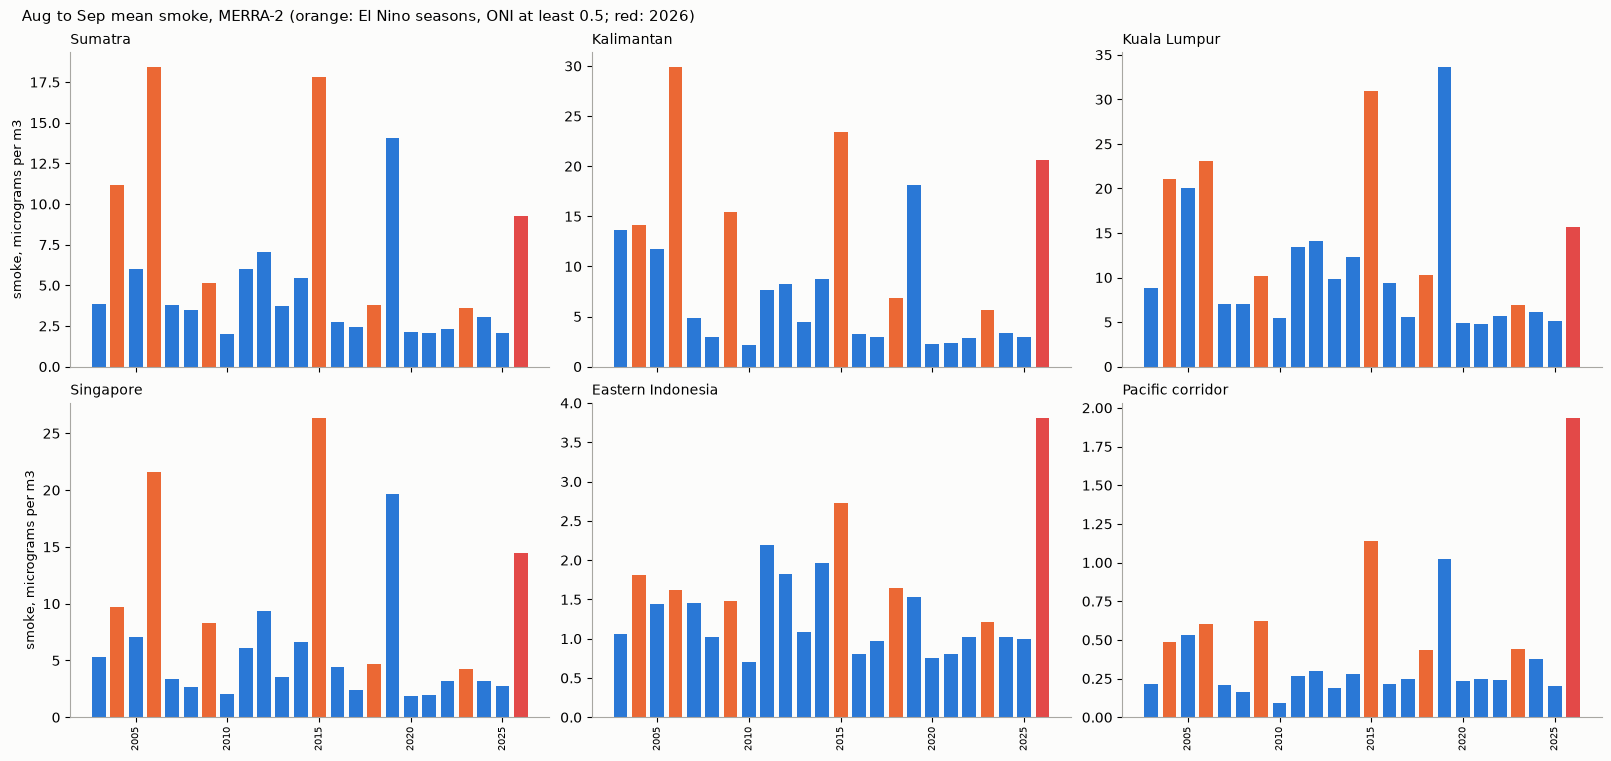

In [9]:
places = ["Sumatra", "Kalimantan", "Kuala Lumpur", "Singapore", "Eastern Indonesia", "Pacific corridor"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True, constrained_layout=True)
yrs = smk.index.values
for ax, place in zip(axes.ravel(), places):
    oni = seas.reindex(yrs)["oni_aso"].values
    cols = ["#e34948" if y == COMPARE_YEAR else ("#eb6834" if (o >= EL_NINO_ONI) else "#2a78d6") for y, o in zip(yrs, oni)]
    ax.bar(yrs, smk[place], color=cols, width=0.75)
    ax.set_title(f"{place}", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel("smoke, micrograms per m3", fontsize=9)
fig.suptitle(f"Aug to Sep mean smoke, MERRA-2 (orange: El Nino seasons, ONI at least {EL_NINO_ONI}; red: {COMPARE_YEAR})", x=0.01, ha="left", fontsize=11)
fig.savefig(FIG_DIR / "season_smoke_by_year.png", dpi=110)
plt.show()

## Section 5 and 6: typhoon days against other days, 23 seasons

For each place and variable: mean anomaly on typhoon days minus mean anomaly on other days, all seasons together, with a 95% interval from resampling whole seasons. Then the same split into El Nino seasons (when there is a lot of smoke to move) and other seasons.

- **Direct export**: smoke flowing into the Pacific corridor through its south side (from eastern Indonesia), and in total through all sides (t/day).
- **Indirect effect**: smoke and PM2.5 in Sumatra, Kalimantan, Kuala Lumpur and Singapore.

In [10]:
def anomalies(s):
    out = []
    for y, g in s.groupby(s.index.year):
        out.append(g - g.rolling(ANOMALY_WINDOW_DAYS, center=True, min_periods=ANOMALY_WINDOW_DAYS // 2).mean())
    return pd.concat(out)


def cluster_boot(a, flag, years):
    uy = np.unique(years)
    by_year = {y: (a[years == y], flag[years == y]) for y in uy}
    diffs = np.empty(BOOT_REPS)
    for r in range(BOOT_REPS):
        pick = rng.choice(uy, size=len(uy))
        xs = np.concatenate([by_year[y][0] for y in pick])
        fs = np.concatenate([by_year[y][1] for y in pick])
        diffs[r] = xs[fs].mean() - xs[~fs].mean() if fs.any() and (~fs).any() else np.nan
    return np.nanpercentile(diffs, [2.5, 97.5])


oni_by_year = seas["oni_aso"]
groups = {"all seasons": lambda y: np.ones(len(y), bool), "El Nino seasons": lambda y: oni_by_year.reindex(y).values >= EL_NINO_ONI, "other seasons": lambda y: oni_by_year.reindex(y).values < EL_NINO_ONI}
targets = [(CORRIDOR, "inflow_south"), (CORRIDOR, "inflow_gross"), (CORRIDOR, "smoke_col"), ("Eastern Indonesia", "smoke"), ("Sumatra", "smoke"), ("Kalimantan", "smoke"), ("Kuala Lumpur", "smoke"), ("Singapore", "smoke"), ("Kuala Lumpur", "pm25"), ("Singapore", "pm25")]
rows = []
for place, var in targets:
    a = anomalies(daily[(place, var)])
    flag_all = TC.reindex(a.index).values
    years_all = a.index.year.values
    base = daily[(place, var)].mean()
    for gname, gsel in groups.items():
        keep = gsel(years_all) & np.isfinite(a.values) & (years_all < COMPARE_YEAR + 1)
        x = a.values[keep]
        f = flag_all[keep]
        yrs_k = years_all[keep]
        if f.sum() < 10:
            continue
        d = x[f].mean() - x[~f].mean()
        lo, hi = cluster_boot(x, f, yrs_k)
        rows.append({"place": place, "variable": var, "group": gname, "seasons": len(np.unique(yrs_k)), "typhoon_days": int(f.sum()), "difference": d, "ci_low": lo, "ci_high": hi, "pct_of_mean": 100 * d / base, "clear": "yes" if (lo > 0 or hi < 0) else ""})
eff = pd.DataFrame(rows)
eff.round(3).to_csv(CLIM_DIR / "typhoon_effects_climatology.csv", index=False)
print("Typhoon days minus other days (anomalies); smoke in micrograms per m3, inflow in t/day:")
print(eff.round(2).to_string(index=False))

Typhoon days minus other days (anomalies); smoke in micrograms per m3, inflow in t/day:
            place     variable           group  seasons  typhoon_days  difference  ci_low  ci_high  pct_of_mean clear
 Pacific corridor inflow_south     all seasons       24           495      158.47   29.13   288.08        29.37   yes
 Pacific corridor inflow_south El Nino seasons        7           185      429.90  244.25   613.07        79.67   yes
 Pacific corridor inflow_south   other seasons       17           310       19.25  -78.85   145.18         3.57      
 Pacific corridor inflow_gross     all seasons       24           495      874.25  121.09  1988.55        32.12   yes
 Pacific corridor inflow_gross El Nino seasons        7           185     1756.95 -296.05  4633.59        64.55      
 Pacific corridor inflow_gross   other seasons       17           310      434.48  116.11   956.95        15.96   yes
 Pacific corridor    smoke_col     all seasons       24           495        0.52    0

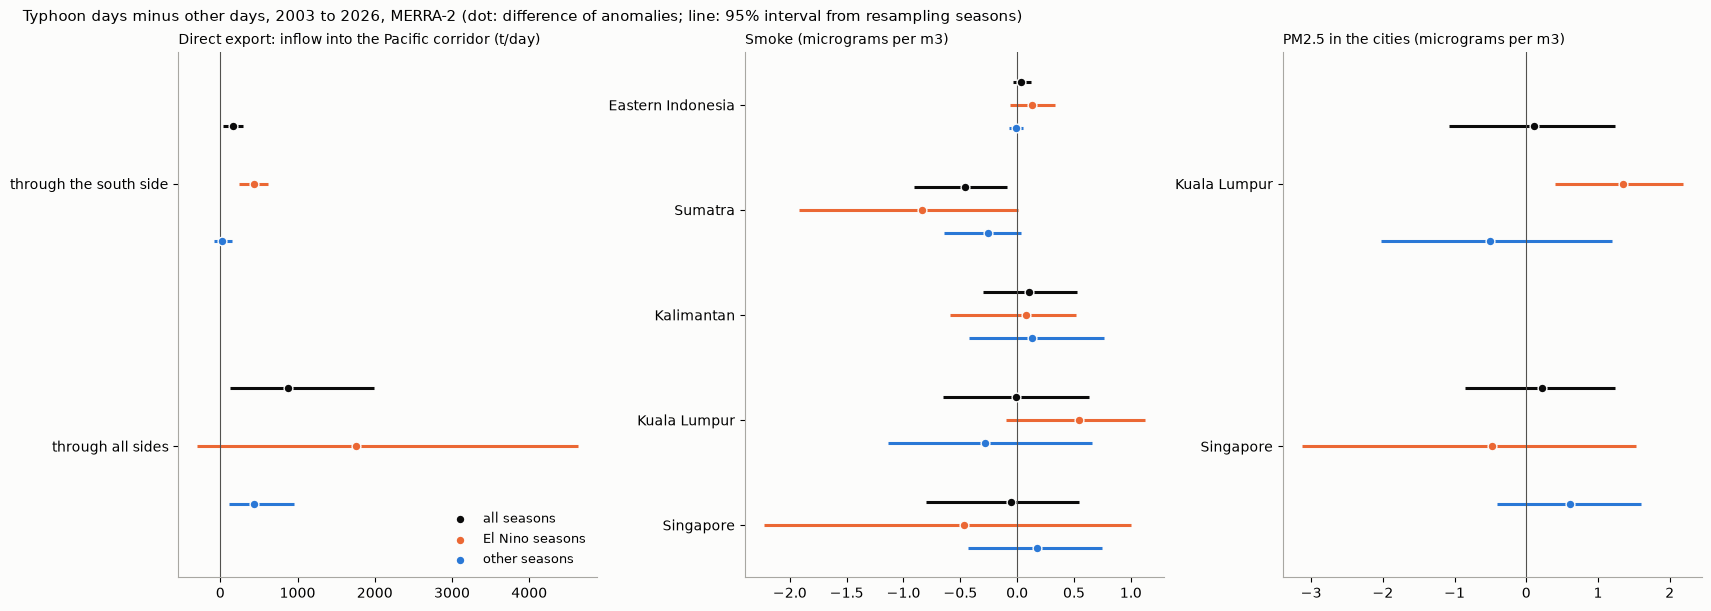

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
group_cols = {"all seasons": "#0b0b0b", "El Nino seasons": "#eb6834", "other seasons": "#2a78d6"}
panels = [("Direct export: inflow into the Pacific corridor (t/day)", [(CORRIDOR, "inflow_south"), (CORRIDOR, "inflow_gross")], {"inflow_south": "through the south side", "inflow_gross": "through all sides"}), ("Smoke (micrograms per m3)", [("Eastern Indonesia", "smoke"), ("Sumatra", "smoke"), ("Kalimantan", "smoke"), ("Kuala Lumpur", "smoke"), ("Singapore", "smoke")], None), ("PM2.5 in the cities (micrograms per m3)", [("Kuala Lumpur", "pm25"), ("Singapore", "pm25")], None)]
for ax, (title, items, lab) in zip(axes, panels):
    ylabels = []
    for i, (place, var) in enumerate(items):
        for j, g in enumerate(group_cols):
            r = eff[(eff["place"] == place) & (eff["variable"] == var) & (eff["group"] == g)]
            if len(r) == 0:
                continue
            y = i + (j - 1) * 0.22
            ax.hlines(y, r["ci_low"], r["ci_high"], color=group_cols[g], lw=2.2)
            ax.scatter(r["difference"], [y], color=group_cols[g], s=40, zorder=5, edgecolor="#fcfcfb", label=g if i == 0 else None)
        ylabels.append(lab[var] if lab else place)
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_yticks(range(len(items)))
    ax.set_yticklabels(ylabels)
    ax.set_ylim(len(items) - 0.5, -0.5)
    ax.set_title(title, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle(f"Typhoon days minus other days, {T[0].year} to {T[-1].year}, MERRA-2 (dot: difference of anomalies; line: 95% interval from resampling seasons)", x=0.01, ha="left", fontsize=11)
fig.savefig(FIG_DIR / "typhoon_effects_climatology.png", dpi=110)
plt.show()

## Section 7: day by day around a typhoon's entry

An "entry" is the first typhoon day after at least three days without one. For each entry, the anomalies from 5 days before to 10 days after are lined up and averaged over all entries (shading: 95% interval from resampling entries).

Typhoon entries into the Philippine Sea box: 103


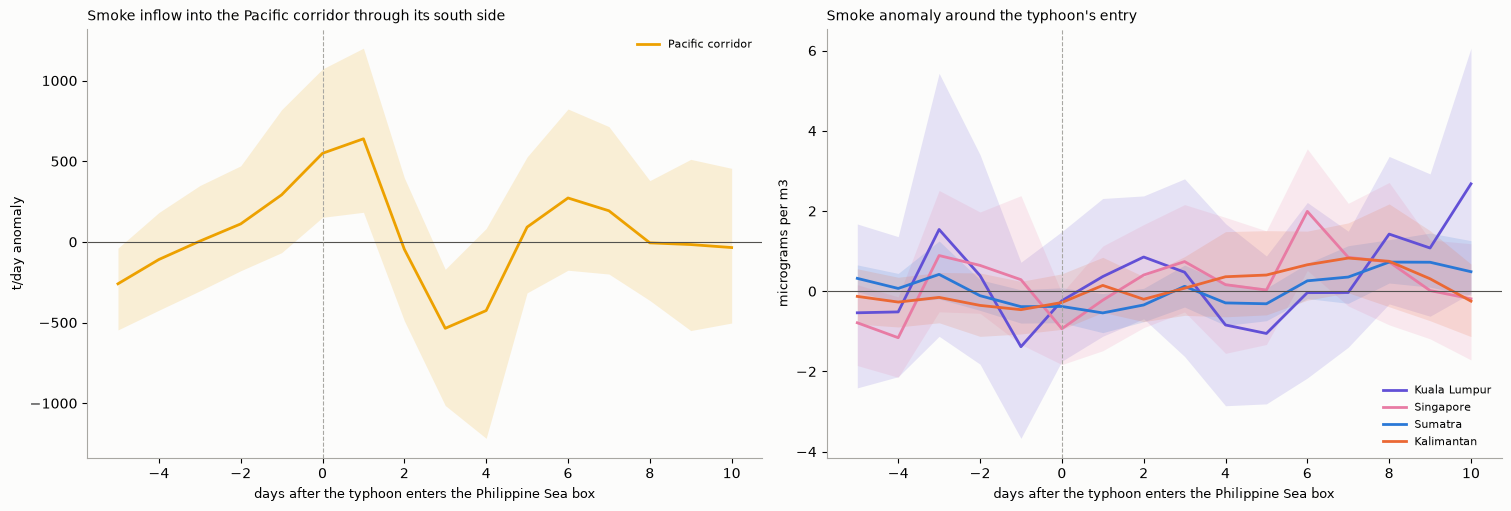

In [12]:
tc_series = TC.copy()
entries = []
for y, g in tc_series.groupby(tc_series.index.year):
    v = g.values
    for i in range(len(v)):
        if v[i] and (i >= QUIET_DAYS) and not v[i - QUIET_DAYS:i].any():
            entries.append(g.index[i])
print("Typhoon entries into the Philippine Sea box:", len(entries))
lags = np.arange(LAG_DAYS[0], LAG_DAYS[1] + 1)
lag_items = [(CORRIDOR, "inflow_south"), ("Kuala Lumpur", "smoke"), ("Singapore", "smoke"), ("Sumatra", "smoke"), ("Kalimantan", "smoke")]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
lag_out = {}
for place, var in lag_items:
    a = anomalies(daily[(place, var)])
    mat = []
    for e in entries:
        idx = [e + pd.Timedelta(days=int(l)) for l in lags]
        vals = a.reindex(idx).values
        if np.isfinite(vals).sum() >= len(lags) - 2:
            mat.append(vals)
    mat = np.array(mat)
    mean = np.nanmean(mat, axis=0)
    boots = np.array([np.nanmean(mat[rng.integers(0, len(mat), len(mat))], axis=0) for _ in range(1000)])
    lo, hi = np.nanpercentile(boots, [2.5, 97.5], axis=0)
    lag_out[f"{place} {var}"] = mean
    ax = axes[0] if var.startswith("inflow") else axes[1]
    col = REGION_COLORS[place]
    ax.plot(lags, mean, color=col, lw=2, label=place)
    ax.fill_between(lags, lo, hi, color=col, alpha=0.15, lw=0)
for ax, title, unit in [(axes[0], "Smoke inflow into the Pacific corridor through its south side", "t/day anomaly"), (axes[1], "Smoke anomaly around the typhoon's entry", "micrograms per m3")]:
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.axvline(0, color="#a8a7a2", lw=0.8, ls="--")
    ax.set_xlabel("days after the typhoon enters the Philippine Sea box", fontsize=9)
    ax.set_ylabel(unit, fontsize=9)
    ax.set_title(title, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG_DIR / "typhoon_entry_composite.png", dpi=110)
plt.show()
pd.DataFrame(lag_out, index=lags).round(2).to_csv(CLIM_DIR / "typhoon_entry_composite.csv")

## Section 8: where the typhoon-day difference is clear

For each season: the typhoon-day minus other-day difference of smoke anomalies at every grid point. The map is the mean over seasons; dots mark grid points where the seasons agree well enough (t-test across seasons, |t| above 2.07, about 95%).

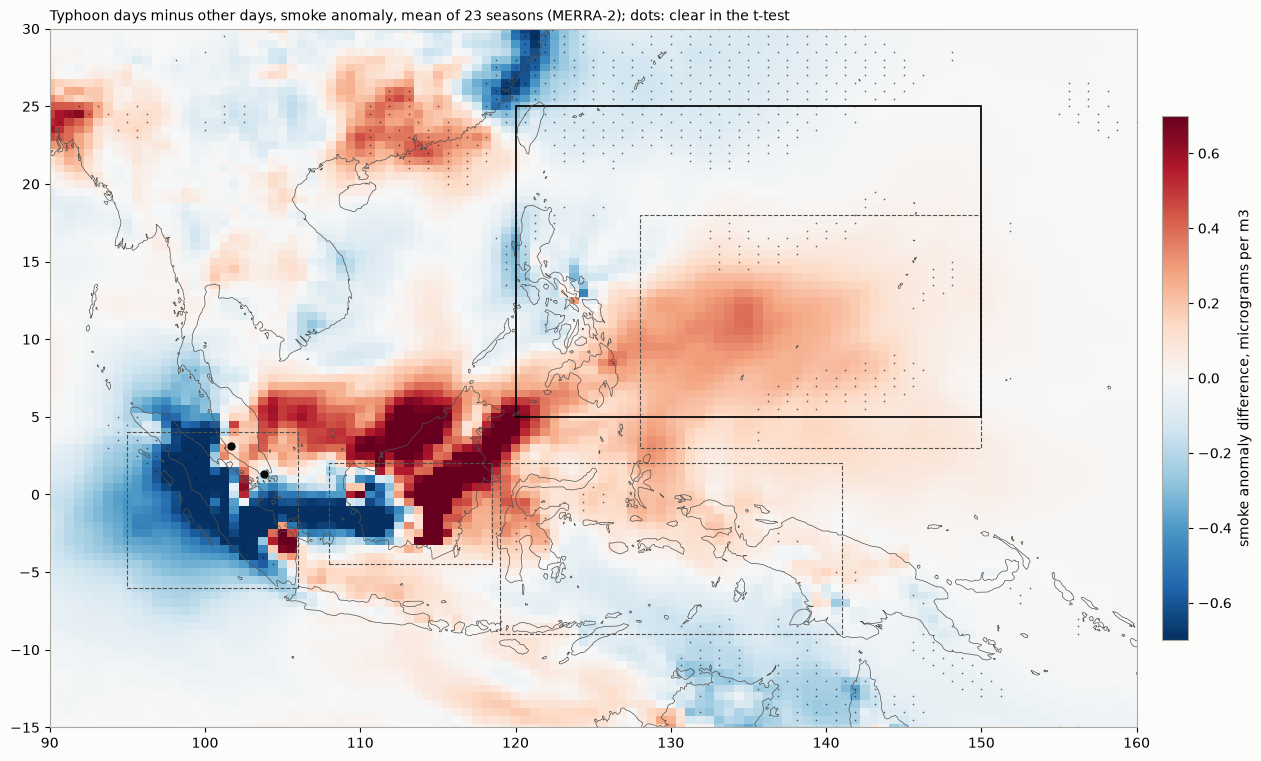

In [13]:
yearly = []
for y in sorted(set(T.year)):
    sel = T.year == y
    if sel.sum() < 60 or y >= COMPARE_YEAR:
        continue
    s = m2["smoke"].isel(time=np.where(sel)[0])
    an = s - s.rolling(time=ANOMALY_WINDOW_DAYS, center=True, min_periods=ANOMALY_WINDOW_DAYS // 2).mean()
    f = xr.DataArray(TC.values[sel], coords={"time": s.time}, dims="time")
    if f.sum() == 0 or (~f).sum() == 0:
        continue
    yearly.append((an.where(f).mean("time") - an.where(~f).mean("time")).values)
yearly = np.array(yearly)
mean_map = np.nanmean(yearly, axis=0)
tstat = mean_map / (np.nanstd(yearly, axis=0, ddof=1) / np.sqrt(len(yearly)))
coast = []
for feat in json.loads((COAST_DIR / "ne_50m_coastline.geojson").read_text(encoding="utf8"))["features"]:
    g = feat["geometry"]
    coast += [np.array(c) for c in (g["coordinates"] if g["type"] == "MultiLineString" else [g["coordinates"]])]
fig, ax = plt.subplots(figsize=(13, 7.5), constrained_layout=True)
lim = float(np.nanpercentile(np.abs(mean_map), 98))
mesh = ax.pcolormesh(LON, LAT, mean_map, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
yy, xx = np.meshgrid(LAT, LON, indexing="ij")
sig = np.abs(tstat) > 2.07
ax.scatter(xx[sig][::2], yy[sig][::2], s=1.5, color="#0b0b0b", alpha=0.6, lw=0)
for line in coast:
    ax.plot(line[:, 0], line[:, 1], color="#52514e", lw=0.5)
for name, b in REGIONS.items():
    ax.add_patch(plt.Rectangle((b[0], b[2]), b[1] - b[0], b[3] - b[2], fill=False, lw=0.8, ls="--", ec="#52514e"))
ax.add_patch(plt.Rectangle((120, 5), 30, 20, fill=False, lw=1.3, ec="#0b0b0b"))
for c, (la, lo) in CITIES.items():
    ax.scatter([lo], [la], s=25, color="#0b0b0b", zorder=5)
ax.set_xlim(LON[0], LON[-1])
ax.set_ylim(LAT[0], LAT[-1])
ax.set_aspect("equal")
fig.colorbar(mesh, ax=ax, shrink=0.75, pad=0.01).set_label("smoke anomaly difference, micrograms per m3")
ax.set_title(f"Typhoon days minus other days, smoke anomaly, mean of {len(yearly)} seasons (MERRA-2); dots: clear in the t-test", loc="left", fontsize=10)
fig.savefig(FIG_DIR / "typhoon_difference_map.png", dpi=110)
plt.show()

___
**END**